# Ticket classification evaluation without MCP

Three fresh runs of the revised 100-ticket reference dataset, using direct Python resource reads and saving functions. No MCP client, server, protocol messages or subprocess is used during collection.

The model chooses the same resource/tool calls as in the MCP workflow. MCP terminology, function names and legacy response keys are retained to keep model inputs comparable. The catalog is a checked-in snapshot.

Per-ticket statistics describe each recorded attempt. Token totals include only usage returned by successful responses; failed-attempt usage is unavailable.


In [1]:
import hashlib
import os
import sys
from pathlib import Path
from typing import get_args

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv
from IPython.display import display
from sklearn.metrics import confusion_matrix


RUN_ANALYSIS = False
N_RUNS = 3
CONCURRENCY = 3
BASE_URL = "http://127.0.0.1:8001"
EXPERIMENT_NOTE = (
    "Revised 100-ticket dataset; three fresh direct Python runs; "
    "no automatic retries"
)

ROOT = Path.cwd()
while not (ROOT / "backend/app").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Run this notebook from the project folder.")
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "backend"))
from app.schemas.types import (  # noqa: E402
    TicketCategory,
    TicketPriority,
    TicketSentiment,
)
from app.validation.evaluation_reporting import (  # noqa: E402
    estimate_costs,
    plot_matrix,
    report_run,
)
from app.validation.evaluation_runner import (  # noqa: E402
    backend_version,
    read_json,
    run_experiment,
)


DATA_FILE = ROOT / "backend/app/validation/scoring_tickets_100_draft.json"
EXPERIMENT_DIR = DATA_FILE.parent / "evaluation_results_direct"
load_dotenv(ROOT / "backend/app/.env", override=False)
MODEL = os.getenv("OPENAI_MODEL", "gpt-6-luna").strip()
LABELS = {
    "category": list(get_args(TicketCategory)),
    "sentiment": list(get_args(TicketSentiment)),
    "priority": list(get_args(TicketPriority)),
}

## 1. Reference data

The `expected` labels are used only for scoring. They are never sent to the API.


In [2]:
tickets = read_json(DATA_FILE)
assert len(tickets) == 100
assert len({ticket["id"] for ticket in tickets}) == 100
assert N_RUNS == 3 and 1 <= CONCURRENCY <= 3
for ticket in tickets:
    for field, labels in LABELS.items():
        assert ticket["expected"][field] in labels

settings = {
    "dataset_hash": hashlib.sha256(DATA_FILE.read_bytes()).hexdigest(),
    **backend_version(ROOT),
    "model": MODEL,
    "experiment_note": EXPERIMENT_NOTE,
    "labels": LABELS,
    "base_url": BASE_URL,
    "concurrency": CONCURRENCY,
    "n_runs": N_RUNS,
    "transport": "direct",
    "catalog_hash": hashlib.sha256(
        (ROOT / "backend/app/services/direct_ticket_catalog.json").read_bytes()
    ).hexdigest(),
}

class_counts = []
for field, labels in LABELS.items():
    for label in labels:
        count = sum(ticket["expected"][field] == label for ticket in tickets)
        class_counts.append({"task": field, "label": label, "count": count})
class_counts = pd.DataFrame(class_counts)
display(class_counts)

,task,label,count
0,category,General,12
1,category,Access,16
2,category,Billing,16
3,category,API,16
4,category,Bug,16
5,category,Feature Request,12
6,category,Performance,12
7,sentiment,Negative,28
8,sentiment,Neutral,54
9,sentiment,Positive,18


## 2. Optional direct collection

Start the updated backend with `DEBUG=True` and confirm the model. Set `RUN_ANALYSIS=True` and run all cells to collect 3 x 100 fresh analyses. The collector sends `?transport=direct` and checks the response transport; it never falls back to MCP. Each attempt is saved, including failures, with no automatic retries. Switch back to `False` afterward to rebuild reports from saved responses.

For a different configuration use a fresh `EXPERIMENT_DIR`. Leave the backend otherwise idle during measurements. Original MCP reports remain in `evaluation_results`.


In [3]:
run_dirs = [EXPERIMENT_DIR / f"run_{i:02d}" for i in range(1, N_RUNS + 1)]
if RUN_ANALYSIS:
    run_experiment(run_dirs, tickets, settings)
else:
    print("Using saved responses. No API calls.")

Using saved responses. No API calls.


## 3. Saved reports

Generate predictions, scores, confusion matrices, timings and token reports.



 run_01

 run_02

 run_03


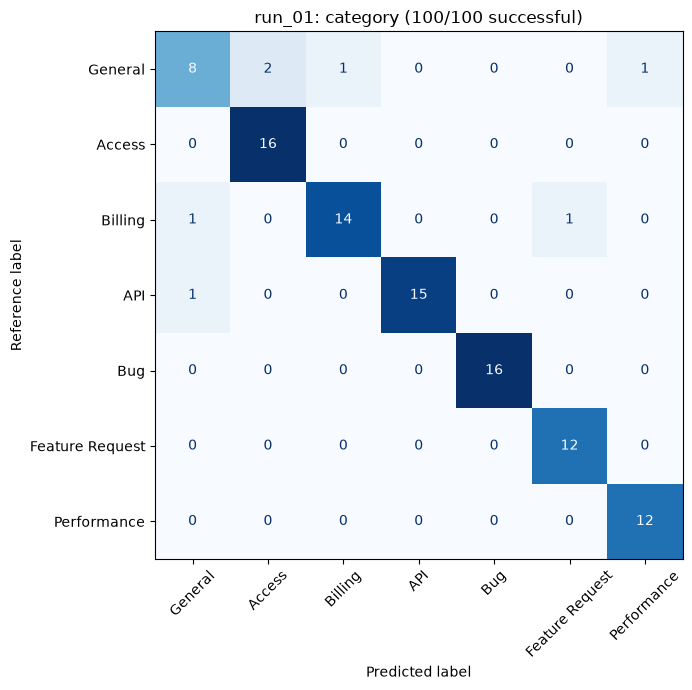

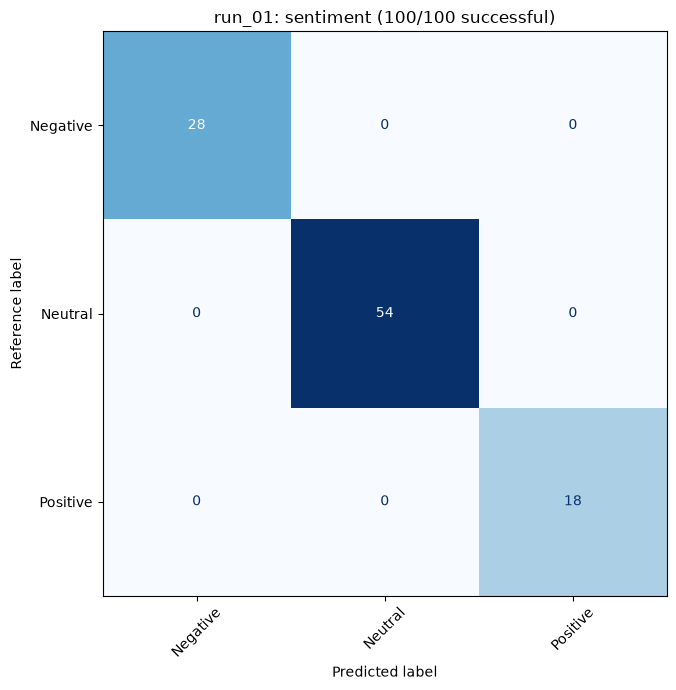

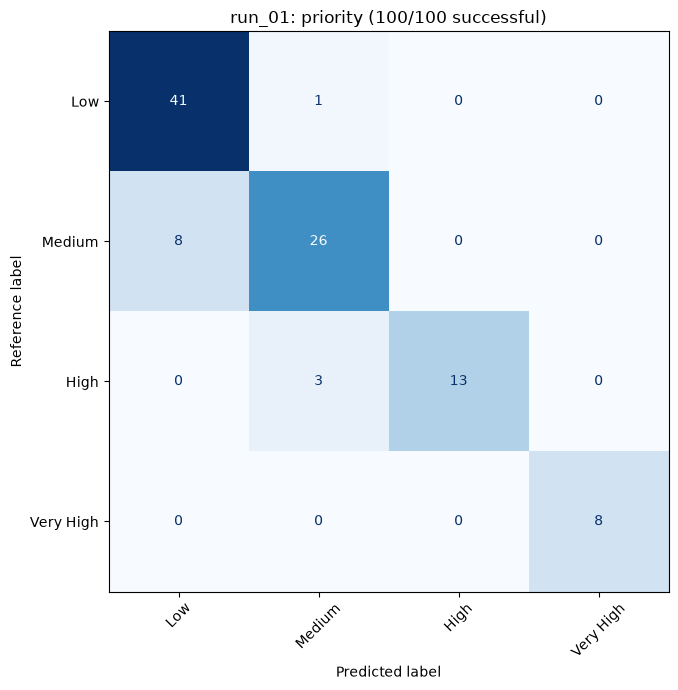

,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_01,category,100,100,1.0,0.93,0.9241,0.9256,0.9228,0.93
1,run_01,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
2,run_01,priority,100,100,1.0,0.88,0.9259,0.8883,0.9025,0.88


,run,attempts_recorded,retried_tickets,previous_failed_attempts,previous_attempt_seconds,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_01,100,0,0,0,100,0,0,527.745,True,100,15.646,4.11,14.418,24.196,100,0,901055,9010.55,104993,1049.93,1006048,10060.48


,id,backend_ticket_id,status,analysis_seconds,input_tokens,output_tokens,total_tokens
0,SCORE-001,MCP-444DF6FF,success,22.814493,9200,1278,10478
1,SCORE-002,MCP-DC88E3FF,success,16.717288,9393,1456,10849
2,SCORE-003,MCP-D995513D,success,17.218309,8771,932,9703
3,SCORE-004,MCP-411C70CA,success,13.173241,8919,969,9888
4,SCORE-005,MCP-AA13DA80,success,20.199674,8942,1110,10052
5,SCORE-006,MCP-DDF0B264,success,19.242659,8686,828,9514
6,SCORE-007,MCP-76F4D5FF,success,14.387648,8954,936,9890
7,SCORE-008,MCP-3B494447,success,11.141645,8826,886,9712
8,SCORE-009,MCP-422233C3,success,15.592042,8956,1072,10028
9,SCORE-010,MCP-380212DF,success,15.337658,9032,1174,10206


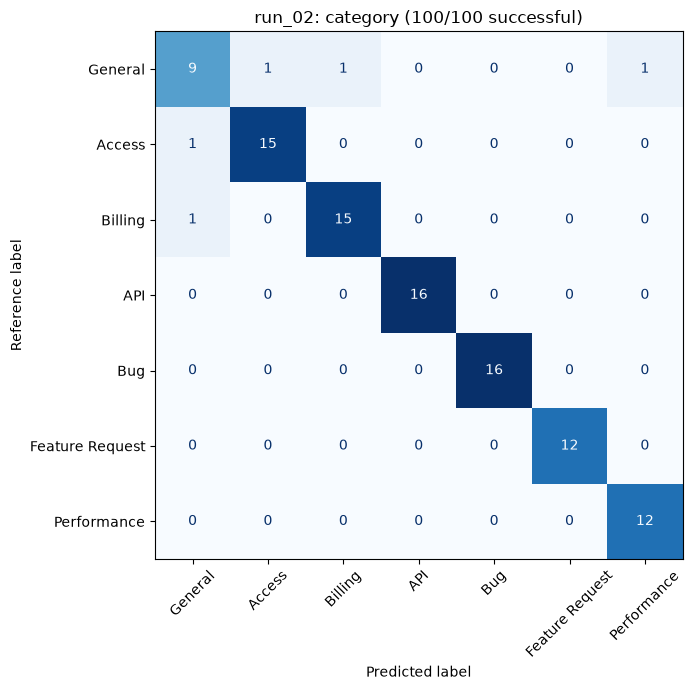

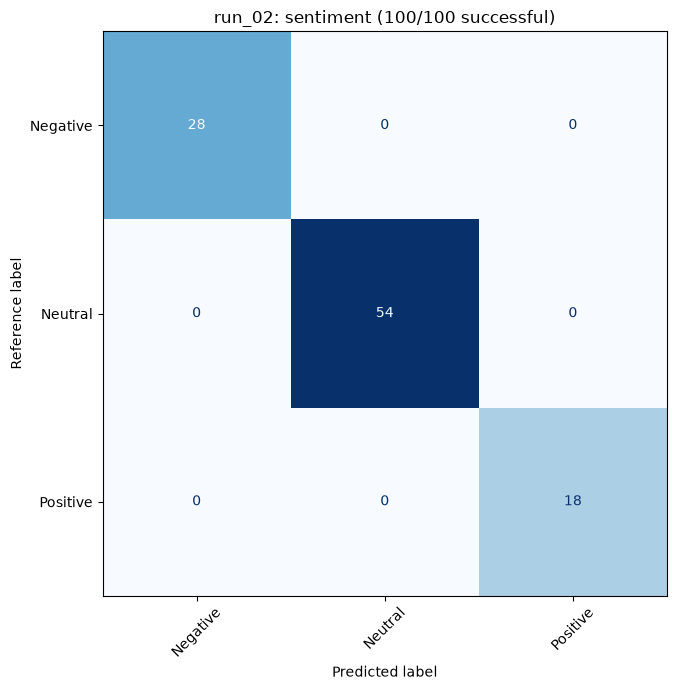

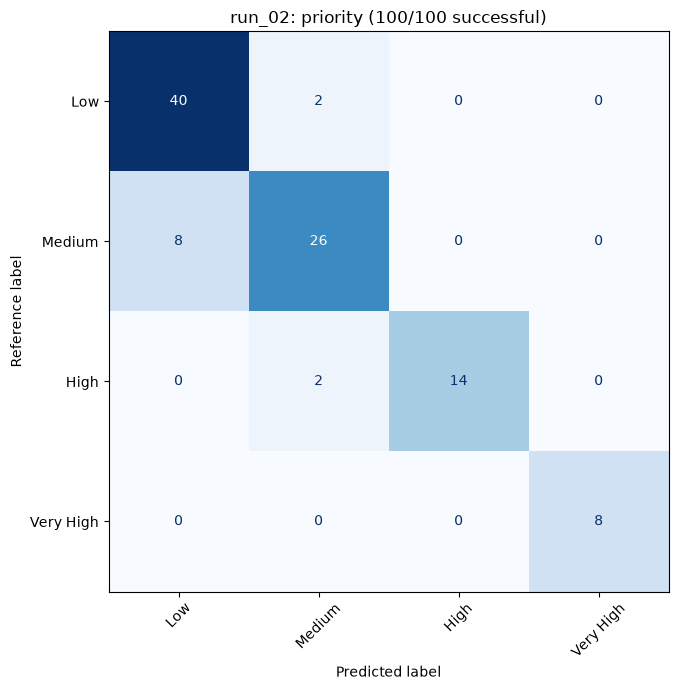

,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_02,category,100,100,1.0,0.95,0.9452,0.9464,0.9454,0.95
1,run_02,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
2,run_02,priority,100,100,1.0,0.88,0.9250,0.8980,0.9087,0.88


,run,attempts_recorded,retried_tickets,previous_failed_attempts,previous_attempt_seconds,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_02,100,0,0,0,100,0,0,541.15,True,100,16.056,5.105,14.235,25.498,100,0,909148,9091.48,105618,1056.18,1014766,10147.66


,id,backend_ticket_id,status,analysis_seconds,input_tokens,output_tokens,total_tokens
0,SCORE-001,MCP-8C0FE07F,success,15.707971,9389,1396,10785
1,SCORE-002,MCP-B9DC0A46,success,16.165386,9230,1272,10502
2,SCORE-003,MCP-7F25005C,success,14.647431,9066,1092,10158
3,SCORE-004,MCP-FE1EC220,success,18.817454,9001,1099,10100
4,SCORE-005,MCP-DBF8E66B,success,15.199967,9078,1096,10174
5,SCORE-006,MCP-03830385,success,14.168077,8851,1043,9894
6,SCORE-007,MCP-55A9216D,success,12.657652,8920,943,9863
7,SCORE-008,MCP-3F7DDB7C,success,11.963403,9094,1054,10148
8,SCORE-009,MCP-1745427C,success,13.683219,9025,1121,10146
9,SCORE-010,MCP-3767D14F,success,36.300157,9088,1189,10277


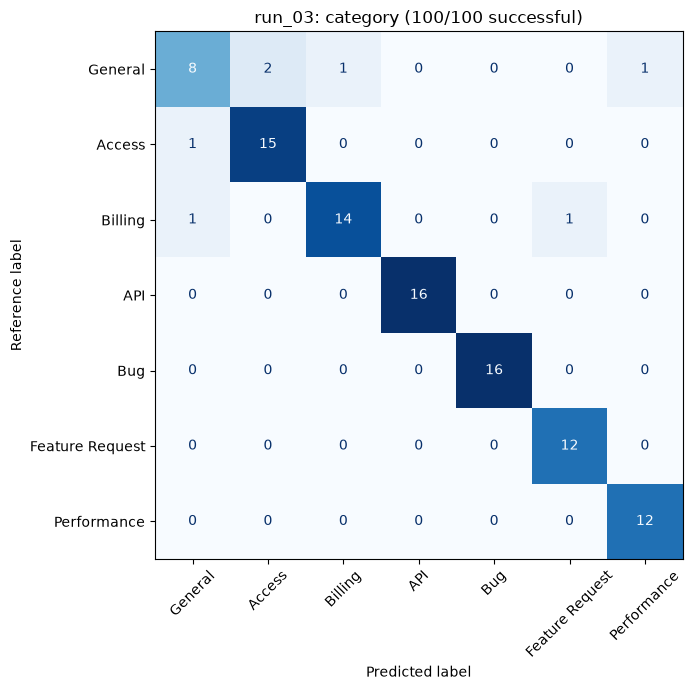

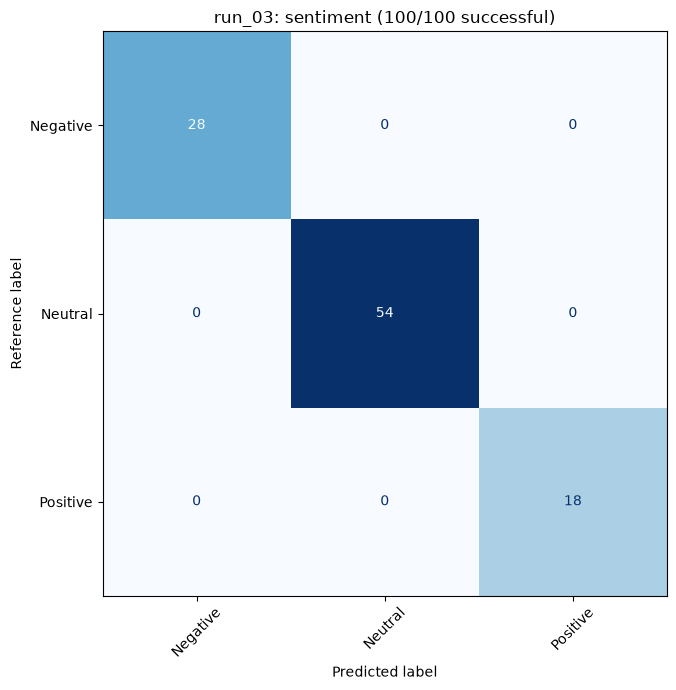

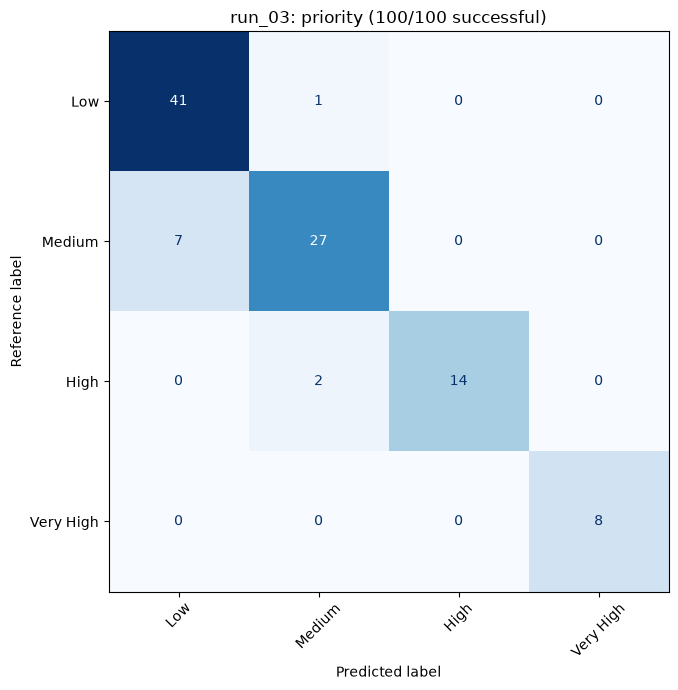

,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_03,category,100,100,1.0,0.93,0.9231,0.9256,0.9228,0.93
1,run_03,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
2,run_03,priority,100,100,1.0,0.90,0.9385,0.9113,0.9220,0.90


,run,attempts_recorded,retried_tickets,previous_failed_attempts,previous_attempt_seconds,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_03,101,1,1,19.255,100,0,0,526.545,True,100,14.972,2.571,14.879,19.319,100,0,903591,9035.91,106306,1063.06,1009897,10098.97


,id,backend_ticket_id,status,analysis_seconds,input_tokens,output_tokens,total_tokens
0,SCORE-001,MCP-13261033,success,17.427816,9082,1170,10252
1,SCORE-002,MCP-63C5320E,success,17.472682,9290,1377,10667
2,SCORE-003,MCP-E9ECFFCD,success,14.536052,8953,1073,10026
3,SCORE-004,MCP-0C72A47F,success,15.064620,8942,904,9846
4,SCORE-005,MCP-7E1AF1B0,success,17.925714,9262,1274,10536
5,SCORE-006,MCP-18C049D3,success,14.910970,8940,994,9934
6,SCORE-007,MCP-E60D235D,success,14.339389,8834,936,9770
7,SCORE-008,MCP-E414C555,success,13.643874,8990,1092,10082
8,SCORE-009,MCP-A202B737,success,15.799332,9226,1310,10536
9,SCORE-010,MCP-3B6D8D5D,success,15.113517,9194,1127,10321


In [4]:
all_predictions, all_metrics, runtime_rows, loaded_settings = [], [], [], []
for run_dir in run_dirs:
    result_path = run_dir / "results.json"
    if not result_path.exists():
        print(run_dir.name, "- no saved results")
        continue
    saved = read_json(result_path)
    assert saved["settings"]["dataset_hash"] == settings["dataset_hash"], (
        "Reference dataset differs."
    )
    assert saved["settings"]["labels"] == LABELS, "Label definitions differ."
    loaded_settings.append(saved["settings"])
    assert all(s == loaded_settings[0] for s in loaded_settings), (
        "Runs have different experiment settings."
    )
    print("\n", run_dir.name)
    predictions, metrics, stats = report_run(
        saved,
        run_dir,
        tickets,
        LABELS,
        class_counts,
        include_previous_attempts=True,
    )
    all_predictions.append(predictions)
    all_metrics.append(metrics)
    runtime_rows.append(stats)

## 4. Compare runs

Mean and sample SD are calculated from complete runs. These summaries describe the retained successful subset; SD is not a confidence interval.


In [5]:
if all_metrics:
    summary_dir = EXPERIMENT_DIR / "comparison"
    summary_dir.mkdir(parents=True, exist_ok=True)
    comparison = pd.concat(all_metrics, ignore_index=True)
    details = pd.concat(all_predictions, ignore_index=True)
    runtime = pd.DataFrame(runtime_rows)
    complete_runs = comparison.groupby("run").coverage.min()
    complete_runs = complete_runs[complete_runs == 1].index.tolist()
    complete = comparison[comparison.run.isin(complete_runs)]
    metric_columns = [
        "accuracy",
        "macro_precision",
        "macro_recall",
        "macro_f1",
        "correct_over_total",
    ]
    average = complete.groupby("task")[metric_columns].agg(
        ["count", "mean", "std"]
    )
    average.columns = [f"{metric}_{stat}" for metric, stat in average.columns]
    display(comparison.round(4))
    display(average.round(4))
    print(
        f"Complete runs: {len(complete_runs)}/{N_RUNS}. "
        "SD is sample SD across runs, not a confidence interval."
    )
    comparison.to_csv(summary_dir / "metrics_by_run.csv", index=False)
    average.to_csv(summary_dir / "metrics_mean_std.csv")
    details.to_csv(summary_dir / "all_ticket_results.csv", index=False)
    runtime.to_csv(summary_dir / "runtime_tokens_by_run.csv", index=False)
    display(runtime.round(3))
    runtime_complete = runtime[runtime.run.isin(complete_runs)]
    numeric_columns = runtime_complete.select_dtypes(include="number").columns
    runtime_average = (
        runtime_complete[numeric_columns].agg(["count", "mean", "std"]).T
    )
    runtime_average.to_csv(summary_dir / "runtime_tokens_mean_std.csv")
    display(runtime_average.round(3))

else:
    print("No saved runs found.")

Complete runs: 3/3. SD is sample SD across runs, not a confidence interval.


,run,task,total,successful,coverage,accuracy,macro_precision,macro_recall,macro_f1,correct_over_total
0,run_01,category,100,100,1.0,0.93,0.9241,0.9256,0.9228,0.93
1,run_01,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
2,run_01,priority,100,100,1.0,0.88,0.9259,0.8883,0.9025,0.88
3,run_02,category,100,100,1.0,0.95,0.9452,0.9464,0.9454,0.95
4,run_02,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
5,run_02,priority,100,100,1.0,0.88,0.9250,0.8980,0.9087,0.88
6,run_03,category,100,100,1.0,0.93,0.9231,0.9256,0.9228,0.93
7,run_03,sentiment,100,100,1.0,1.00,1.0000,1.0000,1.0000,1.00
8,run_03,priority,100,100,1.0,0.90,0.9385,0.9113,0.9220,0.90


,accuracy_count,accuracy_mean,accuracy_std,macro_precision_count,macro_precision_mean,macro_precision_std,macro_recall_count,macro_recall_mean,macro_recall_std,macro_f1_count,macro_f1_mean,macro_f1_std,correct_over_total_count,correct_over_total_mean,correct_over_total_std
task,,,,,,,,,,,,,,,
category,3,0.9367,0.0115,3,0.9308,0.0125,3,0.9325,0.0120,3,0.9303,0.013,3,0.9367,0.0115
priority,3,0.8867,0.0115,3,0.9298,0.0076,3,0.8992,0.0115,3,0.9111,0.010,3,0.8867,0.0115
sentiment,3,1.0000,0.0000,3,1.0000,0.0000,3,1.0000,0.0000,3,1.0000,0.000,3,1.0000,0.0000


,run,attempts_recorded,retried_tickets,previous_failed_attempts,previous_attempt_seconds,successful,failed,missing_or_interrupted,run_wall_seconds,wall_time_complete,timed_tickets,latency_mean_seconds,latency_std_seconds,latency_median_seconds,latency_p95_seconds,usage_available_tickets,usage_missing_tickets,observed_input_tokens,mean_input_tokens_where_available,observed_output_tokens,mean_output_tokens_where_available,observed_total_tokens,mean_total_tokens_where_available
0,run_01,100,0,0,0.000,100,0,0,527.745,True,100,15.646,4.110,14.418,24.196,100,0,901055,9010.55,104993,1049.93,1006048,10060.48
1,run_02,100,0,0,0.000,100,0,0,541.150,True,100,16.056,5.105,14.235,25.498,100,0,909148,9091.48,105618,1056.18,1014766,10147.66
2,run_03,101,1,1,19.255,100,0,0,526.545,True,100,14.972,2.571,14.879,19.319,100,0,903591,9035.91,106306,1063.06,1009897,10098.97


,count,mean,std
attempts_recorded,3.0,100.333,0.577
retried_tickets,3.0,0.333,0.577
previous_failed_attempts,3.0,0.333,0.577
previous_attempt_seconds,3.0,6.418,11.117
successful,3.0,100.000,0.000
failed,3.0,0.000,0.000
missing_or_interrupted,3.0,0.000,0.000
run_wall_seconds,3.0,531.814,8.108
timed_tickets,3.0,100.000,0.000
latency_mean_seconds,3.0,15.558,0.547


## 5. Pooled matrices and agreement

The pooled matrices contain 300 decisions on the same 100 tickets. Pooled macro-F1 differs from mean run-level F1. Agreement measures consistency, not correctness.


Reports saved to: C:\Users\lenovo\Documents\thesis\backend\app\validation\evaluation_results_direct


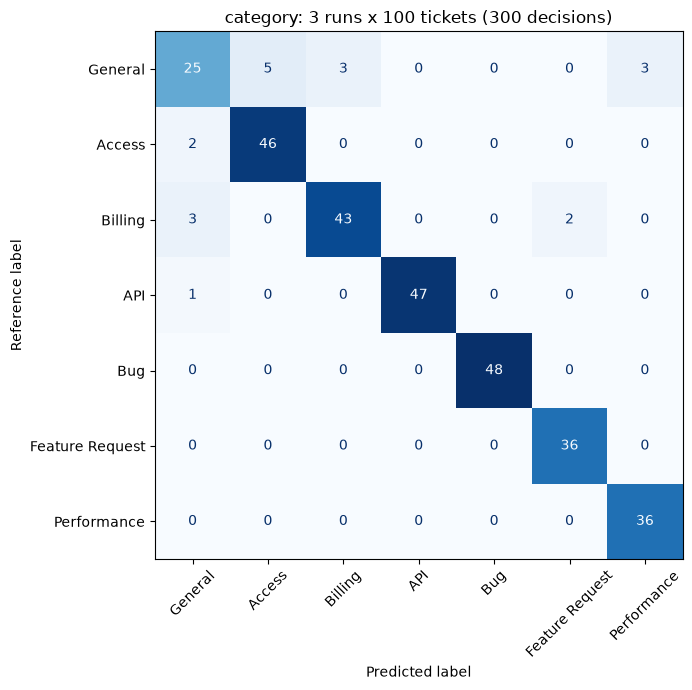

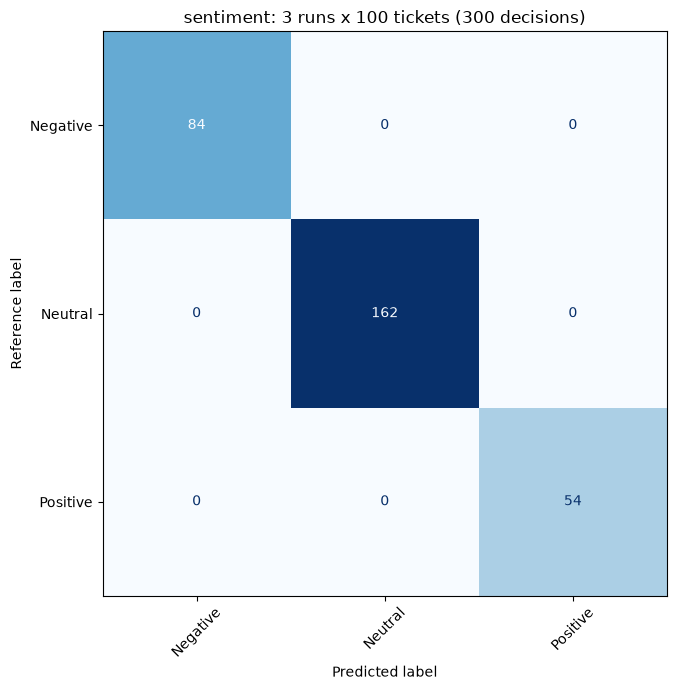

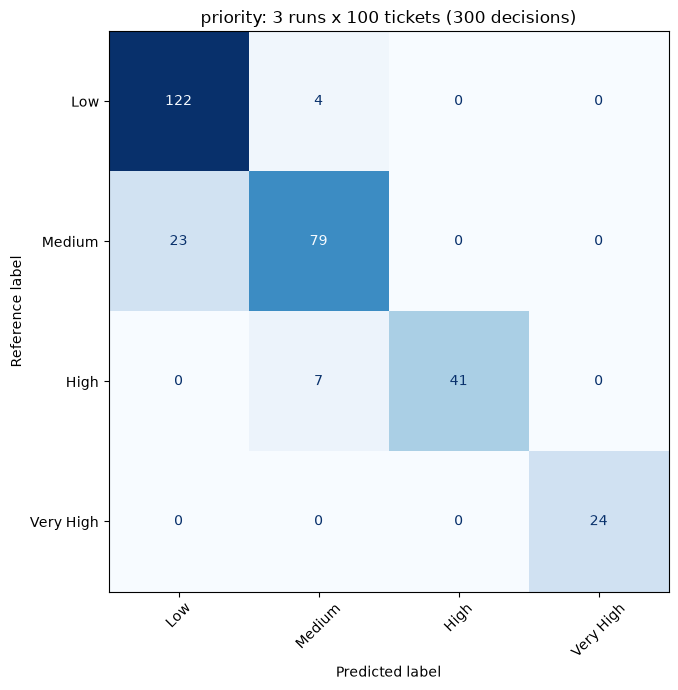

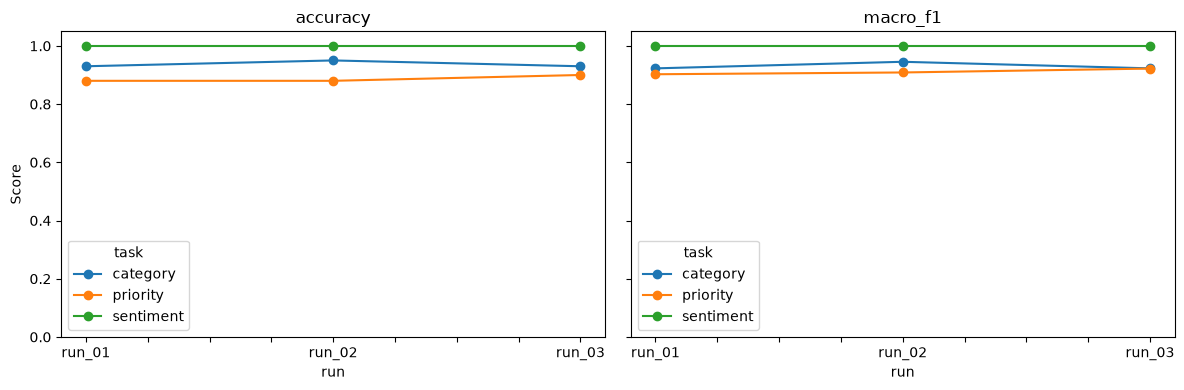

,task,all_runs_agree,changed_between_runs,agreement_rate
0,category,96,4,0.96
1,sentiment,100,0,1.00
2,priority,95,5,0.95


In [6]:
if all_metrics:
    pooled = details[details.run.isin(complete_runs)]
    if len(pooled):
        for field, labels in LABELS.items():
            matrix = confusion_matrix(
                pooled[f"expected_{field}"],
                pooled[f"predicted_{field}"],
                labels=labels,
            )
            pd.DataFrame(matrix, index=labels, columns=labels).to_csv(
                summary_dir / f"pooled_confusion_{field}.csv"
            )
            plot_matrix(
                matrix,
                labels,
                f"{field}: {len(complete_runs)} runs x "
                f"{len(tickets)} tickets ({len(pooled)} decisions)",
                summary_dir / f"pooled_confusion_{field}",
            )
        fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
        for ax, metric in zip(axes, ["accuracy", "macro_f1"]):
            comparison.pivot(index="run", columns="task", values=metric).plot(
                marker="o", ax=ax
            )
            ax.set(title=metric, ylim=(0, 1.05), ylabel="Score")
        fig.tight_layout()
        fig.savefig(summary_dir / "run_comparison.png", dpi=200)
        fig.savefig(summary_dir / "run_comparison.pdf")
        plt.show()
        plt.close(fig)

    if len(complete_runs) == N_RUNS:
        stability = []
        for field in LABELS:
            wide = pooled.pivot(
                index="id", columns="run", values=f"predicted_{field}"
            )
            consistent = wide.nunique(axis=1) == 1
            stability.append(
                {
                    "task": field,
                    "all_runs_agree": int(consistent.sum()),
                    "changed_between_runs": int((~consistent).sum()),
                    "agreement_rate": consistent.mean(),
                }
            )
            wide.assign(all_runs_agree=consistent).to_csv(
                summary_dir / f"stability_{field}_by_ticket.csv"
            )
        stability = pd.DataFrame(stability)
        stability.to_csv(summary_dir / "stability.csv", index=False)
        display(stability)
    else:
        print("Stability requires all configured runs to be fully successful.")
    print("Reports saved to:", EXPERIMENT_DIR.resolve())
else:
    print(
        "No saved runs. Configure the experiment "
        "and enable RUN_ANALYSIS to collect results."
    )

## 6. Estimated API cost

[Standard OpenAI rates](https://developers.openai.com/api/docs/pricing), checked
2026-11-11: **$0.10/M input tokens** and **$0.50/M output tokens** for `gpt-6-luna`.
Estimates use uncached rates and recorded usage; missing usage, cache adjustments,
surcharges, taxes and hosting are excluded.


In [7]:
if runtime_rows:
    cost_by_run, cost_summary = estimate_costs(
        pd.DataFrame(runtime_rows).assign(method="Direct Python"),
        loaded_settings[0]["model"],
    )
    display(cost_by_run.round(6), cost_summary.round(6))
    cost_by_run.to_csv(summary_dir / "cost_by_run.csv", index=False)
    cost_summary.to_csv(summary_dir / "cost_summary.csv")
else:
    print("No saved usage available for cost estimates.")

,method,run,usage_available_tickets,usage_missing_tickets,observed_input_tokens,observed_output_tokens,pricing_model,pricing_date,input_usd_per_million,output_usd_per_million,estimated_input_cost_usd,estimated_output_cost_usd,estimated_total_cost_usd,mean_ticket_cost_usd
0,Direct Python,run_01,100,0,901055,104993,gpt-6-luna,2026-11-11,0.1,0.5,0.090106,0.052496,0.142602,0.001426
1,Direct Python,run_02,100,0,909148,105618,gpt-6-luna,2026-11-11,0.1,0.5,0.090915,0.052809,0.143724,0.001437
2,Direct Python,run_03,100,0,903591,106306,gpt-6-luna,2026-11-11,0.1,0.5,0.090359,0.053153,0.143512,0.001435


,runs,tickets_with_usage,tickets_without_usage,estimated_total_cost_usd,mean_run_cost_usd,std_run_cost_usd,mean_ticket_cost_usd
method,,,,,,,
Direct Python,3,300,0,0.429838,0.143279,0.000596,0.001433
